## Task 1

In [35]:
# Import in the astropy fit reader
from astropy.io import fits
# Here we will use the level 1 EIS file from the project as an example
# It is more complicated as contains imaging spectroscopy data (x,y,wavelength), 
# over several different spectral windows, so multiple 3D arrays of data
# Load in the file header, data and data headers
# Headers contain extra useful information
hdu=fits.open('eis_l1_20130515_014637.fits')
hdr=hdu[0].header
data=hdu[1].data
dhdr=hdu[1].header
hdu.close()
import numpy as np
# Let's print out the names of all the spectral windows in this file
typeids=[f'TTYPE{x}' for x in 1+np.arange(11)]
for t in typeids:
    print(t,' is ', dhdr[t])

TTYPE1  is  FE X 184.540
TTYPE2  is  FE XXIV 192.030
TTYPE3  is  CA XVII 192.830
TTYPE4  is  FE XII 195.120
TTYPE5  is  O V 248.480
TTYPE6  is  FE XVII 255.050
TTYPE7  is  FE XVI 262.980
TTYPE8  is  FE XXIII 263.690
TTYPE9  is  FE XIV 264.780
TTYPE10  is  FE XIV 274.200
TTYPE11  is  FE XV 284.160


## We need the following Wavelengths
• O V 248.480Å: log 𝑇max ∼ 5.4(TTYPE5)

• Fe XVI 262.980Å: log 𝑇max ∼ 6.4(TTYPE6)

• Fe XVII 255.050Å: log 𝑇max ∼ 6.7(TTYPE7)

## Let us Load the data files for different wavelengths
### For O V

In [36]:
# Let's extract the data for O V 248.480Å
data_O_V=data[dhdr["TTYPE5"]]
# We need to flip the x-data (as EIS rasters right to left)
# Then transpose as python expects y,x not x,y when plotting images
data_O_V=np.transpose(np.flip(data_O_V,axis=0))
# Now you have a 3D array of this spectral window data 
# and it is in units of detected photons, i.e. DN

# Now create an array for the wavelength values in this spectral window
# Spectral windows info in the header is the min, max and number of bins
wvl_O_V=np.linspace(dhdr["TWMIN5"],dhdr["TWMAX5"],dhdr["TDETXW5"])
# Just print them out to check they are as expected
print("Wavelength of O V:","\n",wvl_O_V)
print("Data of O_V:","\n",data_O_V)
# These are in units of Angstrom (1e-10 m or 0.1 nm)

Wavelength of O V: 
 [248.30679971 248.32907419 248.35134867 248.37362315 248.39589763
 248.41817211 248.44044659 248.46272107 248.48499555 248.50727003
 248.52954451 248.55181899 248.57409347 248.59636795 248.61864243
 248.64091691]
Data of O_V: 
 [[[ 5.526296   3.6841974  2.3026235 ...  2.763148   3.6841974  6.9078703]
  [ 4.605247   4.144722   4.605247  ...  4.605247   6.4473457  5.0657716]
  [ 4.144722   5.0657716  6.9078703 ...  5.9868207  5.0657716  2.763148 ]
  ...
  [ 6.4473457  9.671019   8.289444  ... 12.434167   8.289444   9.671019 ]
  [ 9.440756  12.664429  10.361806  ... 11.74338   11.052592  11.513117 ]
  [ 9.440756  12.664429  10.361806  ... 11.74338   11.052592  11.513117 ]]

 [[ 5.526792   6.90849    6.447924  ...  6.90849    3.6845279  7.829622 ]
  [ 5.526792   6.90849    6.90849   ...  6.447924   6.447924   6.447924 ]
  [ 5.526792   6.447924   7.3690557 ...  5.987358   5.066226   5.526792 ]
  ...
  [ 6.447924   8.750754   8.290188  ...  8.290188   7.3690557  4.60566 

## for Fe XVI

In [37]:
# Let's extract the data for O V 248.480Å
data_fe_XVI=data[dhdr["TTYPE7"]]
# We need to flip the x-data (as EIS rasters right to left)
# Then transpose as python expects y,x not x,y when plotting images
data_fe_XVI=np.transpose(np.flip(data_fe_XVI,axis=0))
# Now you have a 3D array of this spectral window data 
# and it is in units of detected photons, i.e. DN

# Now create an array for the wavelength values in this spectral window
# Spectral windows info in the header is the min, max and number of bins
wvl_fe_XVI=np.linspace(dhdr["TWMIN7"],dhdr["TWMAX7"],dhdr["TDETXW7"])
# Just print them out to check they are as expected
print("Wavelength of Fe VI:","\n",wvl_fe_XVI)
print("Data of Fe_VI:","\n",data_fe_XVI)
# These are in units of Angstrom (1e-10 m or 0.1 nm)

Wavelength of Fe VI: 
 [262.71295144 262.73520861 262.75746578 262.77972295 262.80198012
 262.82423729 262.84649445 262.86875162 262.89100879 262.91326596
 262.93552313 262.9577803  262.98003747 263.00229463 263.0245518
 263.04680897 263.06906614 263.09132331 263.11358048 263.13583765
 263.15809482 263.18035198 263.20260915 263.22486632]
Data of Fe_VI: 
 [[[ 4.872432    7.308648    4.872432   ...  5.3596754   4.3851886
    6.3341618 ]
  [ 4.3851886   6.821405    4.3851886  ...  5.8469186   3.8979456
    5.3596754 ]
  [ 4.3851886   6.821405    5.3596754  ...  6.821405    3.4107025
    4.872432  ]
  ...
  [ 1.9489728   5.8469186   4.3851886  ...  4.872432    4.872432
    5.3596754 ]
  [ 1.7053512   4.6288104   3.4107025  ...  5.1160536   4.3851886
    6.09054   ]
  [ 1.4617296   3.4107025   2.436216   ...  5.3596754   3.8979456
    6.821405  ]]

 [[ 5.3601294   6.334698    5.3601294  ...  6.334698    6.334698
    4.3855605 ]
  [ 4.3855605   6.334698    4.3855605  ...  4.8728447   5.36012

## for Fe XVII

In [38]:
# Let's extract the data for O V 248.480Å
data_fe_XVII=data[dhdr["TTYPE6"]]
# We need to flip the x-data (as EIS rasters right to left)
# Then transpose as python expects y,x not x,y when plotting images
data_fe_XVII=np.transpose(np.flip(data_fe_XVII,axis=0))
# Now you have a 3D array of this spectral window data 
# and it is in units of detected photons, i.e. DN

# Now create an array for the wavelength values in this spectral window
# Spectral windows info in the header is the min, max and number of bins
wvl_fe_XVII=np.linspace(dhdr["TWMIN6"],dhdr["TWMAX6"],dhdr["TDETXW6"])
# Just print them out to check they are as expected
print("Wavelength of Fe XVII:","\n",wvl_fe_XVII)
print("Data of Fe_XVII:","\n",data_fe_XVII)
# These are in units of Angstrom (1e-10 m or 0.1 nm)

Wavelength of Fe XVII: 
 [254.6094691  254.63173574 254.65400237 254.67626901 254.69853564
 254.72080228 254.74306891 254.76533555 254.78760218 254.80986882
 254.83213546 254.85440209 254.87666873 254.89893536 254.921202
 254.94346863 254.96573527 254.9880019  255.01026854 255.03253517
 255.05480181 255.07706844 255.09933508 255.12160171 255.14386835
 255.16613498 255.18840162 255.21066826 255.23293489 255.25520153
 255.27746816 255.2997348  255.32200143 255.34426807 255.3665347
 255.38880134 255.41106797 255.43333461 255.45560124 255.47786788]
Data of Fe_XVII: 
 [[[ 5.194354    6.138782    3.305498   ...  5.194354    7.08321
    4.249926  ]
  [ 0.47221398  4.249926    7.08321    ...  6.138782    3.7777119
    0.47221398]
  [12.749778   10.860922    6.610996   ...  7.5554237   5.194354
    5.194354  ]
  ...
  [ 7.08321     6.610996    8.0276375  ...  4.249926    5.666568
    6.610996  ]
  [ 6.610996    4.72214     4.72214    ...  3.305498    4.72214
    4.72214   ]
  [ 6.610996    4.72

## Now Let's Load the Errors

In [39]:
# Load in the file header, data and data headers
# Headers contain extra useful information
hdu1=fits.open('eis_er_20130515_014637.fits')
hdr1=hdu1[0].header
data1=hdu1[1].data
dhdr1=hdu1[1].header
hdu1.close()

The Structure of the File is the same as that of the Data file

## for O V

In [40]:
# Let's extract the data for O V 248.480Å
er_O_V=data1[dhdr1["TTYPE5"]]
# We need to flip the x-data (as EIS rasters right to left)
# Then transpose as python expects y,x not x,y when plotting images
er_O_V=np.transpose(np.flip(er_O_V,axis=0))
# Now you have a 3D array of this spectral window data 
# and it is in units of detected photons, i.e. DN

# Now create an array for the wavelength values in this spectral window
# Spectral windows info in the header is the min, max and number of bins
wvl_O_V_er=np.linspace(dhdr1["TWMIN5"],dhdr1["TWMAX5"],dhdr1["TDETXW5"])
# Just print them out to check they are as expected
print("Wavelength error of O V:","\n",wvl_O_V_er)
print("Data error of O_V:","\n",er_O_V)
# These are in units of Angstrom (1e-10 m or 0.1 nm)

Wavelength error of O V: 
 [248.30679971 248.32907419 248.35134867 248.37362315 248.39589763
 248.41817211 248.44044659 248.46272107 248.48499555 248.50727003
 248.52954451 248.55181899 248.57409347 248.59636795 248.61864243
 248.64091691]
Data error of O_V: 
 [[[   2.5924003    2.2086222    1.8698766 ...    1.9886203    2.2085738
      2.845895 ]
  [   2.4081686    2.3104348    2.4080799 ...    2.4082131    2.7641876
      2.5020447]
  [   2.3103423    2.5015745    2.8461206 ...    2.6795511    2.5016172
      1.989104 ]
  ...
  [   2.7639942    3.2961197    3.079386  ...    3.6913779    3.0795248
      3.29599  ]
  [-100.        -100.        -100.        ... -100.        -100.
   -100.       ]
  [-100.        -100.        -100.        ... -100.        -100.
   -100.       ]]

 [[   2.5925372    2.8464923    2.7644083 ...    2.846079     2.208697
      3.0035121]
  [   2.592496     2.8464172    2.8464549 ...    2.7644856    2.7643309
      2.7639053]
  [   2.5922894    2.7640986    2.

## for Fe VI

In [41]:
# Let's extract the data for FeVI 262.980 Å
er_fe_XVI=data1[dhdr1["TTYPE7"]]
# We need to flip the x-data (as EIS rasters right to left)
# Then transpose as python expects y,x not x,y when plotting images
er_fe_XVI=np.transpose(np.flip(er_fe_XVI,axis=0))
# Now you have a 3D array of this spectral window data 
# and it is in units of detected photons, i.e. DN

# Now create an array for the wavelength values in this spectral window
# Spectral windows info in the header is the min, max and number of bins
wvl_fe_XVI_er=np.linspace(dhdr1["TWMIN7"],dhdr1["TWMAX7"],dhdr1["TDETXW7"])
# Just print them out to check they are as expected
print("Wavelength error of Fe XVI:","\n",wvl_fe_XVI_er)
print("Data error of Fe XVI:","\n",er_fe_XVI)
# These are in units of Angstrom (1e-10 m or 0.1 nm)

Wavelength error of Fe XVI: 
 [262.71295144 262.73520861 262.75746578 262.77972295 262.80198012
 262.82423729 262.84649445 262.86875162 262.89100879 262.91326596
 262.93552313 262.9577803  262.98003747 263.00229463 263.0245518
 263.04680897 263.06906614 263.09132331 263.11358048 263.13583765
 263.15809482 263.18035198 263.20260915 263.22486632]
Data error of Fe XVI: 
 [[[   2.4919846    2.9400196    2.4916215 ...    2.588032     2.392084
      2.7690516]
  [   2.3918948    2.855677     2.3914695 ...    2.680176     2.2876275
      2.5878134]
  [   2.391564     2.8563497    2.5879445 ...    2.8559144    2.1781676
      2.4915762]
  ...
  [   1.8117555    2.6803448    2.3916583 ...    2.4920757    2.4920757
   -100.       ]
  [-100.        -100.        -100.        ... -100.        -100.
   -100.       ]
  [   1.6724304    2.1781676    1.9423869 ...    2.587289     2.2874298
      2.8565478]]

 [[   2.5880322    2.769475     2.5876825 ...    2.7700467    2.7698016
      2.3914998]
  [   

## for Fe XVII

In [42]:
# Let's extract the data for Fe VII 255.050Å
er_fe_XVII=data1[dhdr1["TTYPE6"]]
# We need to flip the x-data (as EIS rasters right to left)
# Then transpose as python expects y,x not x,y when plotting images
er_fe_XVII=np.transpose(np.flip(er_fe_XVII,axis=0))
# Now you have a 3D array of this spectral window data 
# and it is in units of detected photons, i.e. DN

# Now create an array for the wavelength values in this spectral window
# Spectral windows info in the header is the min, max and number of bins
wvl_fe_XVII_er=np.linspace(dhdr1["TWMIN6"],dhdr1["TWMAX6"],dhdr1["TDETXW6"])
# Just print them out to check they are as expected
print("Wavelength of Fe XVII:","\n",wvl_fe_XVII_er)
print("Data of Fe XVII:","\n",er_fe_XVII)
# These are in units of Angstrom (1e-10 m or 0.1 nm)

Wavelength of Fe XVII: 
 [254.6094691  254.63173574 254.65400237 254.67626901 254.69853564
 254.72080228 254.74306891 254.76533555 254.78760218 254.80986882
 254.83213546 254.85440209 254.87666873 254.89893536 254.921202
 254.94346863 254.96573527 254.9880019  255.01026854 255.03253517
 255.05480181 255.07706844 255.09933508 255.12160171 255.14386835
 255.16613498 255.18840162 255.21066826 255.23293489 255.25520153
 255.27746816 255.2997348  255.32200143 255.34426807 255.3665347
 255.38880134 255.41106797 255.43333461 255.45560124 255.47786788]
Data of Fe XVII: 
 [[[   2.5399702    2.71877      2.1360228 ...    2.5404456    2.8884149
      2.345723 ]
  [   1.3145313    2.347406     2.8877306 ...    2.7196977    2.244131
      1.3161169]
  [   3.7419899    3.4811573    2.804269  ...    2.968219  -100.
      2.5399702]
  ...
  [   2.8879206    2.804699     3.0476265 ...    2.346751     2.631494
      2.8052073]
  [   2.8045816    2.4444401    2.445427  ...    2.1355605    2.445023
      

# Task 1

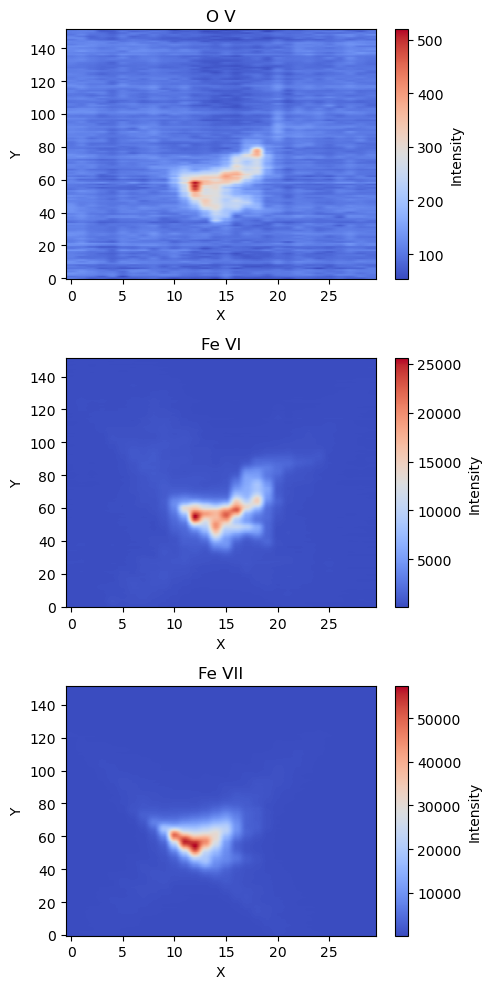

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Sum over the wavelength axis to get 2D intensity maps
imap_O_V = np.sum(data_O_V, axis=0)  # Summing over wavelength(wavelength corresponds to axis 0,(axis runs from 0 to 2))
imap_fe_XVI = np.sum(data_fe_XVI, axis=0)
imap_fe_XVII = np.sum(data_fe_XVII, axis=0)

# Create figure and subplots
fig, axes = plt.subplots(3, 1, figsize=(5, 10))#first two arguments indicate the number of rows and columns for the subplot 
#the argument figsize helps us decide the size of each of the subplots

# Lists of intensity maps and titles
i_maps = [imap_O_V,imap_fe_XVI,imap_fe_XVII]
titles = ["O V", "Fe VI", "Fe VII"]

# Looping through indices to plot all three spectral windows together
for i in range(0,3):
    plot=axes[i].imshow(i_maps[i], origin="lower", aspect="auto",cmap="coolwarm")
    #setting automatic aspect ratio
    #origin is set
    #coolwarm filter chosen to better see the flare
    
    axes[i].set_title(titles[i])#iteratively choosing titles for each subplot 
    axes[i].set_xlabel("X")#setting X title
    axes[i].set_ylabel("Y")#setting Y title
    fig.colorbar(plot, ax=axes[i], label="Intensity")#adds the colourbar legend  

plt.tight_layout()  # Adjust spacing to prevent overlap


## Comment

## Task 2

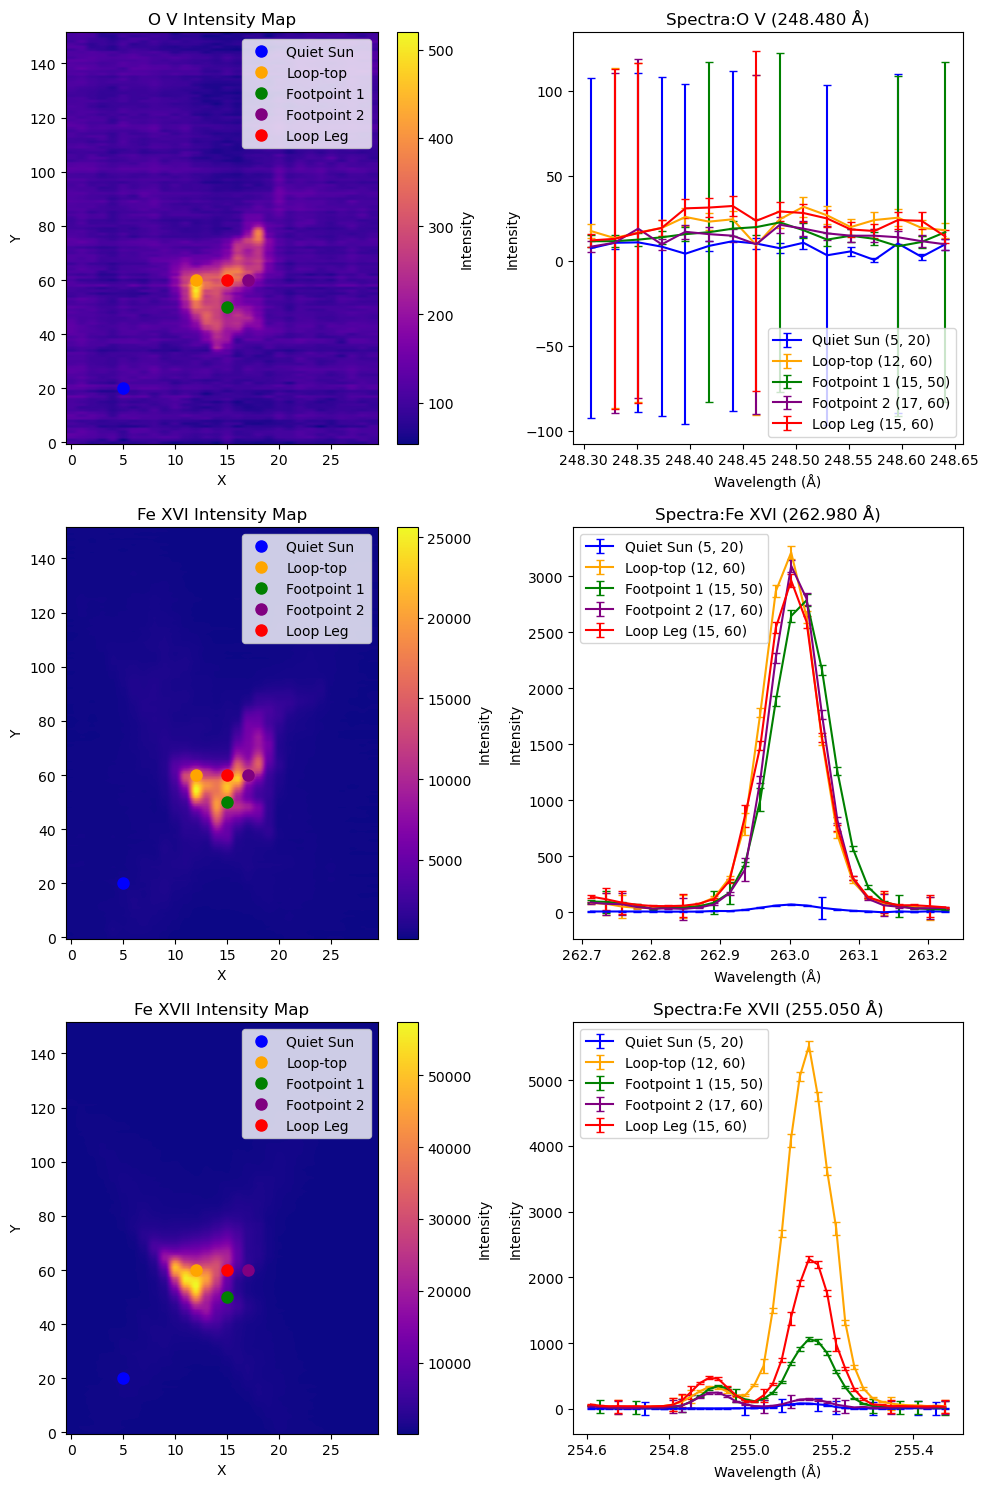

In [44]:
#Defining locations, labels, and corresponding colors
locations = [(5, 20), (12, 60), (15, 50), (17, 60), (15, 60)]
labels = ['Quiet Sun', 'Loop-top', 'Footpoint 1', 'Footpoint 2', 'Loop Leg']
colors = ['blue', 'orange', 'green', 'purple', 'red']


#Creating a 3x2 subplot grid (3 rows, 2 columns)
fig, axes = plt.subplots(3, 2, figsize=(10, 15))

#Data for intensity maps
intensity_maps = [
    (imap_O_V, 'O V Intensity Map', 0),  # Row 1
    (imap_fe_XVI, 'Fe XVI Intensity Map', 1),  # Row 2
    (imap_fe_XVII, 'Fe XVII Intensity Map', 2)  # Row 3
]
#Data for Spectra
spectra_data = [
    (data_O_V, wvl_O_V, er_O_V, 'O V (248.480 Å)', 0),  # Row 1
    (data_fe_XVI, wvl_fe_XVI, er_fe_XVI, 'Fe XVI (262.980 Å)', 1),  # Row 2
    (data_fe_XVII, wvl_fe_XVII, er_fe_XVII, 'Fe XVII (255.050 Å)', 2)  # Row 3
]

# Plot spectra with explicit colors
for j in range(len(spectra_data)):#iteratively selcting data,wavelength error,title and row number for each spectral window
    data, wvl, error, title, row = spectra_data[j]
    ax = axes[row, 1]  # Spectra in the second column during plot
    for k in range(len(locations)):# to iteratively select locations,labels,colours,error and data for corresponding spectral window
        x, y = locations[k]
        label = labels[k]
        color = colors[k]
        spectrum = data[:, y, x]
        err = error[:, y, x]
        ax.errorbar(wvl, spectrum, yerr=err, label=label + " (" + str(x) + ", " + str(y) + ")",capsize=3, color=color)
    
    ax.set_xlabel('Wavelength (Å)')#adding title to x axis of spectra plot
    ax.set_ylabel('Intensity')#y axis title= Intensity
    ax.set_title("Spectra:"+title)#creating dynamic title for separte spectra windows 
    ax.legend()

# Plotting intensity maps with matching colors for markers
for j in range(len(intensity_maps)):
    imap, title, row = intensity_maps[j]
    ax = axes[row, 0]  # Intensity map in the first column
    im = ax.imshow(imap, origin="lower", aspect="auto", cmap="plasma")
    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    fig.colorbar(im, ax=ax, label="Intensity")
    
    # Mark selected pixels with the same colors as the spectra
    for k in range(len(locations)):
        x, y = locations[k]
        label = labels[k]
        color = colors[k]
        ax.plot(x, y, 'o', color=color, markersize=8, label=label)
    
    ax.legend()

# Adjust layout to prevent overlap
plt.tight_layout()

### Comments


## Task3

From 
Fe XVI was the best line for a line profile
study during the flare. Fe XVI is emitted at a laboratory
rest wavelength of 262:9760 Å. It is a strong, well isolated line
with no known blends, making it adequate for a flare spectral
line profile analysis.Additionally FeXVI spectral window shows the parts of the flare with most clarity.

## Task 4


Quiet Sun:
Weighted Amplitude (A): 65.311 ± 5.061
Weighted Mean (μ): 263.002 ± 0.003 Å
Weighted Sigma (σ): 0.043 ± 0.0028 Å
Weighted FWHM: 0.102 ± 0.007 Å
Weighted Reduced χ²: 1.605 (χ²=22, dof=14)
Unweighted Amplitude (A): 63.112 ± 1.629
Unweighted Mean (μ): 263.003 ± 0.001 Å
Unweighted Sigma (σ): 0.041 ± 0.001 Å
Unweighted FWHM: 0.097 ± 0.003 Å
Unweighted Reduced χ²: 5.133 (χ²=72, dof=14)

Loop-top:
Weighted Amplitude (A): 3138.393 ± 34.056
Weighted Mean (μ): 263.0 ± 0.0 Å
Weighted Sigma (σ): 0.039 ± 0.0003 Å
Weighted FWHM: 0.092 ± 0.001 Å
Weighted Reduced χ²: 1.633 (χ²=23, dof=14)
Unweighted Amplitude (A): 3173.756 ± 16.609
Unweighted Mean (μ): 263.0 ± 0.0 Å
Unweighted Sigma (σ): 0.038 ± 0.0 Å
Unweighted FWHM: 0.09 ± 0.001 Å
Unweighted Reduced χ²: 501.212 (χ²=7017, dof=14)

Footpoint 1:
Weighted Amplitude (A): 2765.502 ± 31.605
Weighted Mean (μ): 263.017 ± 0.0 Å
Weighted Sigma (σ): 0.041 ± 0.0004 Å
Weighted FWHM: 0.097 ± 0.001 Å
Weighted Reduced χ²: 0.746 (χ²=10, dof=14)
Unweighted

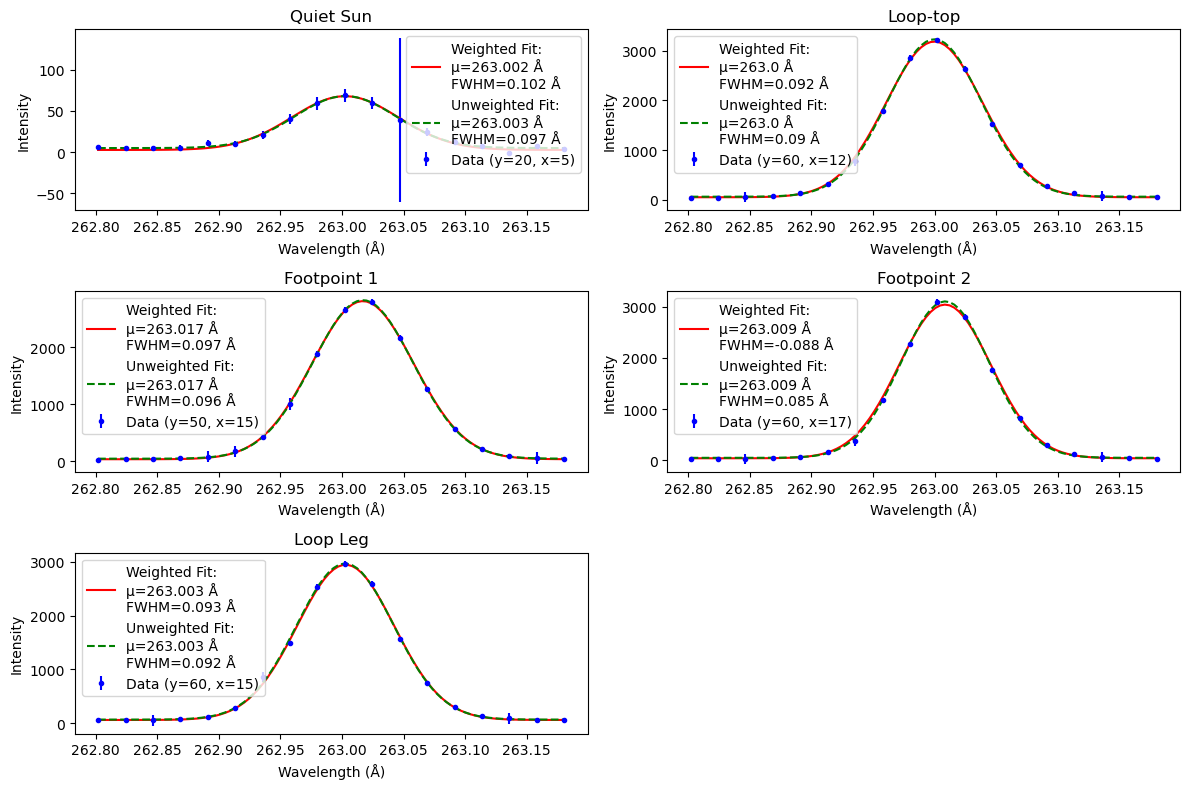

In [55]:
from scipy.optimize import curve_fit

# Define the Gaussian function
def gaus_func(x, A, mu, sigma, c):
    return A * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) + c

# Wavelength array
n_wvl_bins = data_fe_XVI.shape[0]#no of wavelengths 
wvl_fe_XVI = np.linspace(dhdr["TWMIN7"], dhdr["TWMAX7"], n_wvl_bins)#selecting wavelength of Fe XVI

# Fe XVI rest wavelength
fe_XVI = 262.984  # Å
window = 0.2 # corresponding to ±0.2 Å window

# Create wavelength filter
wavelength_filter = (wvl_fe_XVI >= fe_XVI - window) & (wvl_fe_XVI <= fe_XVI + window)#creating a window region to filter wavelengths
xdata = wvl_fe_XVI[wavelength_filter]#filtering the wavelegths in filter region

# Locations to analyze
locations = {
    "Quiet Sun": (20, 5),
    "Loop-top": (60, 12),
    "Footpoint 1": (50, 15),
    "Footpoint 2": (60, 17),
    "Loop Leg": (60, 15)
}

#Storage for Task 5
loc_names = []
sigma_fit_vals = []
sigma_fit_errs = []

# Plot setup
plt.figure(figsize=(12, 8))
i = 1

# Iterate over locations
for j in locations:
    y_idx, x_idx = locations[j]
    spectrum_full = data_fe_XVI[:, y_idx, x_idx]
    errors_full = er_fe_XVI[:, y_idx, x_idx]
    
    ydata = spectrum_full[wavelength_filter]#filtering y data coreesponding to the window 
    sigma = errors_full[wavelength_filter]#filter errors of the wondow region
    
    p0 = [max(ydata), fe_XVI, 0.1, min(ydata)]#initial guess for the gaussian fit
    
    # Weighted fit(with errors)
    fit_params_w, cov_matrix_w = curve_fit(gaus_func, xdata, ydata, p0=p0, sigma=sigma, absolute_sigma=True)#performing the fit
    fit_errors_w = np.sqrt(np.diag(cov_matrix_w))#assigning the errors (diaginal elements of Covariance matrix to a variable)
    
    # Unweighted fit(without errors)
    fit_params_u, cov_matrix_u = curve_fit(gaus_func, xdata, ydata, p0=p0)
    fit_errors_u = np.sqrt(np.diag(cov_matrix_u))
    
    # Extract parameters
    A_w, mu_w, sigma_fit_w, c_w = fit_params_w#extracting different parametrs of the fit
    A_u, mu_u, sigma_fit_u, c_u = fit_params_u
    
    fwhm_w = 2 * np.sqrt(2 * np.log(2)) * sigma_fit_w#calculating FWHM (Jeffrey et al 2016)
    fwhm_u = 2 * np.sqrt(2 * np.log(2)) * sigma_fit_u
    
    residuals_w = ydata - gaus_func(xdata, *fit_params_w)#calculating residuals to be used to find chi^2 value
    residuals_u = ydata - gaus_func(xdata, *fit_params_u)
    
    chi2_w = np.sum((residuals_w / sigma) ** 2)#calculating chi^2 
    chi2_u = np.sum(residuals_u ** 2)
    
    dof = len(ydata) - len(p0)#degree of freedom =no of data points-no of parameters
    reduced_chi2_w = chi2_w / dof#calculating reduced chi^2
    reduced_chi2_u = chi2_u / dof
    
    # Plot results
    plt.subplot(3, 2, i)#plotting the data.same as before.only difference is data is now based on fitted data
    plt.errorbar(xdata, ydata, yerr=sigma, fmt='b.', label="Data (y=" + str(y_idx) + ", x=" + str(x_idx) + ")")#error bar with pixel locations
    xfit = np.linspace(min(xdata), max(xdata), 100)#defining 100 points bw max and min of x
    plt.plot(xfit, gaus_func(xfit, *fit_params_w), 'r', label="Weighted Fit:\nμ=" + str(round(mu_w, 3)) + " Å\nFWHM=" + str(round(fwhm_w, 3)) + " Å")
    plt.plot(xfit, gaus_func(xfit, *fit_params_u), 'g--', label="Unweighted Fit:\nμ=" + str(round(mu_u, 3)) + " Å\nFWHM=" + str(round(fwhm_u, 3)) + " Å")
    plt.xlabel('Wavelength (Å)')
    plt.ylabel('Intensity')
    plt.title(j)
    plt.legend()
    plt.tight_layout()

    # Print results
    print("")
    print(j + ":")
    print("Weighted Amplitude (A): " + str(round(A_w, 3)) + " ± " + str(round(fit_errors_w[0], 3)))
    print("Weighted Mean (μ): " + str(round(mu_w, 3)) + " ± " + str(round(fit_errors_w[1], 3)) + " Å")
    print("Weighted Sigma (σ): " + str(round(sigma_fit_w, 3)) + " ± " + str(abs(round(fit_errors_w[2], 4))) + " Å")
    print("Weighted FWHM: " + str(round(fwhm_w, 3)) + " ± " + str(round(2 * np.sqrt(2 * np.log(2)) * fit_errors_w[2], 3)) + " Å")
    print("Weighted Reduced χ²: " + str(round(reduced_chi2_w, 3)) + " (χ²=" + str(round(chi2_w)) + ", dof=" + str(dof) + ")")
    
    print("Unweighted Amplitude (A): " + str(round(A_u, 3)) + " ± " + str(round(fit_errors_u[0], 3)))
    print("Unweighted Mean (μ): " + str(round(mu_u, 3)) + " ± " + str(round(fit_errors_u[1], 3)) + " Å")
    print("Unweighted Sigma (σ): " + str(round(sigma_fit_u, 3)) + " ± " + str(round(fit_errors_u[2], 3)) + " Å")
    print("Unweighted FWHM: " + str(round(fwhm_u, 3)) + " ± " + str(round(2 * np.sqrt(2 * np.log(2)) * fit_errors_u[2], 3)) + " Å")
    print("Unweighted Reduced χ²: " + str(round(reduced_chi2_u, 3)) + " (χ²=" + str(round(chi2_u)) + ", dof=" + str(dof) + ")")
    
    #Save for Task 5
    loc_names.append(j)
    sigma_fit_vals.append(sigma_fit_w)
    sigma_fit_errs.append(fit_errors_w[2])
    
    i += 1


## Task 5

Result explained in word.aslo look for justification to the equations in the task as green marked sections on Jeffrey et al


broader than thermal.expected.in the paper Jeffrey et al marked.just like in the paper FWHM used for broadening


In [56]:
# Constants
k_B = 1.38064852e-23
c = 3e8
T = 2.5e6
amu = 1.660539e-27
M = 56 * amu
lambda0 = 262.984e-10
sigma_inst = 0.067 / (2 * np.sqrt(2 * np.log(2)))  # Å

# Thermal Broadening 
v_th = np.sqrt(2 * k_B * T / M)
sigma_th = (lambda0 * v_th / (np.sqrt(2) * c)) * 1e10  # convert m to Å

#Storage Lists
locations_list= []
sigma_fit_list = []
sigma_fit_err_list = []
sigma_inst_list = []
sigma_th_list = []
sigma_nt_list = []
sigma_nt_err_list = []

#Loop through locations
for i in range(len(loc_names)):
    loc = loc_names[i]
    sigma_fit = sigma_fit_vals[i]
    sigma_fit_err = sigma_fit_errs[i]

    # Non-thermal width and error
    sigma_nt = np.sqrt(sigma_fit**2 - sigma_inst**2 - sigma_th**2)
    sigma_nt_err = (sigma_fit / sigma_nt) * sigma_fit_err

    # FWHM from sigma_nt
    fwhm_nt = 2 * np.sqrt(2 * np.log(2)) * sigma_nt
    fwhm_nt_err = 2 * np.sqrt(2 * np.log(2)) * sigma_nt_err

    # Store values
    locations_list.append(loc)
    sigma_fit_list.append(sigma_fit)
    sigma_fit_err_list.append(sigma_fit_err)
    sigma_inst_list.append(sigma_inst)
    sigma_th_list.append(sigma_th)
    sigma_nt_list.append(sigma_nt)
    sigma_nt_err_list.append(sigma_nt_err)

    # Print results
    print("")
    print(loc + ":")
    print("FWHM_nt = " + str(round(fwhm_nt, 4)) + " ± " + str(round(fwhm_nt_err, 4)) + " Å")


Quiet Sun:
FWHM_nt = 0.0656 ± 0.0101 Å

Loop-top:
FWHM_nt = 0.0496 ± 0.0014 Å

Footpoint 1:
FWHM_nt = 0.058 ± 0.0014 Å

Footpoint 2:
FWHM_nt = 0.0407 ± -0.0017 Å

Loop Leg:
FWHM_nt = 0.0504 ± 0.0015 Å


In [58]:
# Constants
k_B = 1.38064852e-23
c = 3e8
T = 2.5e6
amu = 1.660539e-27
M = 56 * amu
lambda0 = 262.984e-10
sigma_inst = 0.067 / (2 * np.sqrt(2 * np.log(2)))  # Å

# Thermal Broadening 
v_th = np.sqrt(2 * k_B * T / M)
sigma_th = (lambda0 * v_th / (np.sqrt(2) * c)) * 1e10  # convert m to Å

# Short-named storage lists
locs = []
σ_fit_vals = []
σ_fit_errs = []
σ_inst_vals = []
σ_th_vals = []
σ_nt_vals = []
σ_nt_errs = []

# Loop through locations
for i in range(len(loc_names)):
    loc = loc_names[i]
    σ_fit = sigma_fit_vals[i]
    σ_fit_err = sigma_fit_errs[i]

    σ_nt = np.sqrt(σ_fit**2 - sigma_inst**2 - sigma_th**2)
    σ_nt_err = (σ_fit / σ_nt) * σ_fit_err

    fwhm_nt = 2 * np.sqrt(2 * np.log(2)) * σ_nt
    fwhm_nt_err = 2 * np.sqrt(2 * np.log(2)) * σ_nt_err

    # Append to lists
    locs.append(loc)
    σ_fit_vals.append(σ_fit)
    σ_fit_errs.append(σ_fit_err)
    σ_inst_vals.append(sigma_inst)
    σ_th_vals.append(sigma_th)
    σ_nt_vals.append(σ_nt)
    σ_nt_errs.append(σ_nt_err)

    # Print results
    print("")
    print(loc + ":")
    print("FWHM_nt = " + str(round(fwhm_nt, 4)) + " ± " + str(abs(round(fwhm_nt_err, 4))) + " Å")

    


Quiet Sun:
FWHM_nt = 0.0656 ± 0.0101 Å

Loop-top:
FWHM_nt = 0.0496 ± 0.0014 Å

Footpoint 1:
FWHM_nt = 0.058 ± 0.0014 Å

Footpoint 2:
FWHM_nt = 0.0407 ± 0.0017 Å

Loop Leg:
FWHM_nt = 0.0504 ± 0.0015 Å


In [59]:
# Data
locations = ["Quiet Sun", "Loop-top", "Footpoint 1", "Footpoint 2", "Loop Leg"]
fwhm_nt_vals = [0.0656, 0.0496, 0.0580, 0.0407, 0.0504]
fwhm_nt_errs = [0.0101, 0.0014, 0.0014, 0.0017, 0.0015]

# Print table header
print(f"{'Flare Location':<15} | {'FWHM_nt (Å)':<12} | {'Uncertainty (± Å)':<18}")
print("-" * 52)

# Print each row
for loc, val, err in zip(locations, fwhm_nt_vals, fwhm_nt_errs):
    print(f"{loc:<15} | {val:<12.4f} | {err:<18.4f}")


Flare Location  | FWHM_nt (Å)  | Uncertainty (± Å) 
----------------------------------------------------
Quiet Sun       | 0.0656       | 0.0101            
Loop-top        | 0.0496       | 0.0014            
Footpoint 1     | 0.0580       | 0.0014            
Footpoint 2     | 0.0407       | 0.0017            
Loop Leg        | 0.0504       | 0.0015            


In [60]:
pip install prettytable


In [61]:
from prettytable import PrettyTable

# Create the table
table = PrettyTable()

# Set column headers
table.field_names = ["Flare Location", "FWHMₙₜ (Å)", "Uncertainty (± Å)"]

# Center align all columns
table.align = "c"

# Data
locations = ["Quiet Sun", "Loop-top", "Footpoint 1", "Footpoint 2", "Loop Leg"]
fwhm_nt_vals = [0.0656, 0.0496, 0.0580, 0.0407, 0.0504]
fwhm_nt_errs = [0.0101, 0.0014, 0.0014, -0.0017, 0.0015]

# Add rows
for loc, val, err in zip(locations, fwhm_nt_vals, fwhm_nt_errs):
    table.add_row([loc, f"{val:.4f}", f"{err:.4f}"])

# Print the table
print(table)


+----------------+------------+-------------------+
| Flare Location | FWHMₙₜ (Å) | Uncertainty (± Å) |
+----------------+------------+-------------------+
|   Quiet Sun    |   0.0656   |       0.0101      |
|    Loop-top    |   0.0496   |       0.0014      |
|  Footpoint 1   |   0.0580   |       0.0014      |
|  Footpoint 2   |   0.0407   |      -0.0017      |
|    Loop Leg    |   0.0504   |       0.0015      |
+----------------+------------+-------------------+
